In [1]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pattern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")


Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl


/tmp/ipykernel_551484/873917099.py:42: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  sessions = pickle.load(f)


Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.284346,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-1.066838,-0.565258,-0.636459,-0.953344
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.458511,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-1.007153,-0.565216,-0.636034,-0.862807
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,0.632677,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.947469,-0.565174,-0.635609,-0.772271
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,0.806842,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.887785,-0.565133,-0.635184,-0.681734
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,1.072744,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.890066,-0.563833,-0.621913,-0.537591


Scanning 19 sessions...


/tmp/ipykernel_551484/2729334808.py:147: RuntimeWarning: Mean of empty slice
  mu_actual = np.nanmean(stack, axis=0)
/tmp/ipykernel_551484/2729334808.py:156: RuntimeWarning: Mean of empty slice
  shuff_means.append(np.nanmean(s_stack, axis=0))
/tmp/ipykernel_551484/2729334808.py:156: RuntimeWarning: Mean of empty slice
  shuff_means.append(np.nanmean(s_stack, axis=0))



--- Aggregation Complete ---
Discovered Hemispheres: ['L', 'R']
Discovered Colors:      ['G', 'R']
Genotypes: ['KI', 'WT']
Regions: ['DLS', 'DMS', 'VS']

=== Plotting: L Hemisphere | G Channel ===


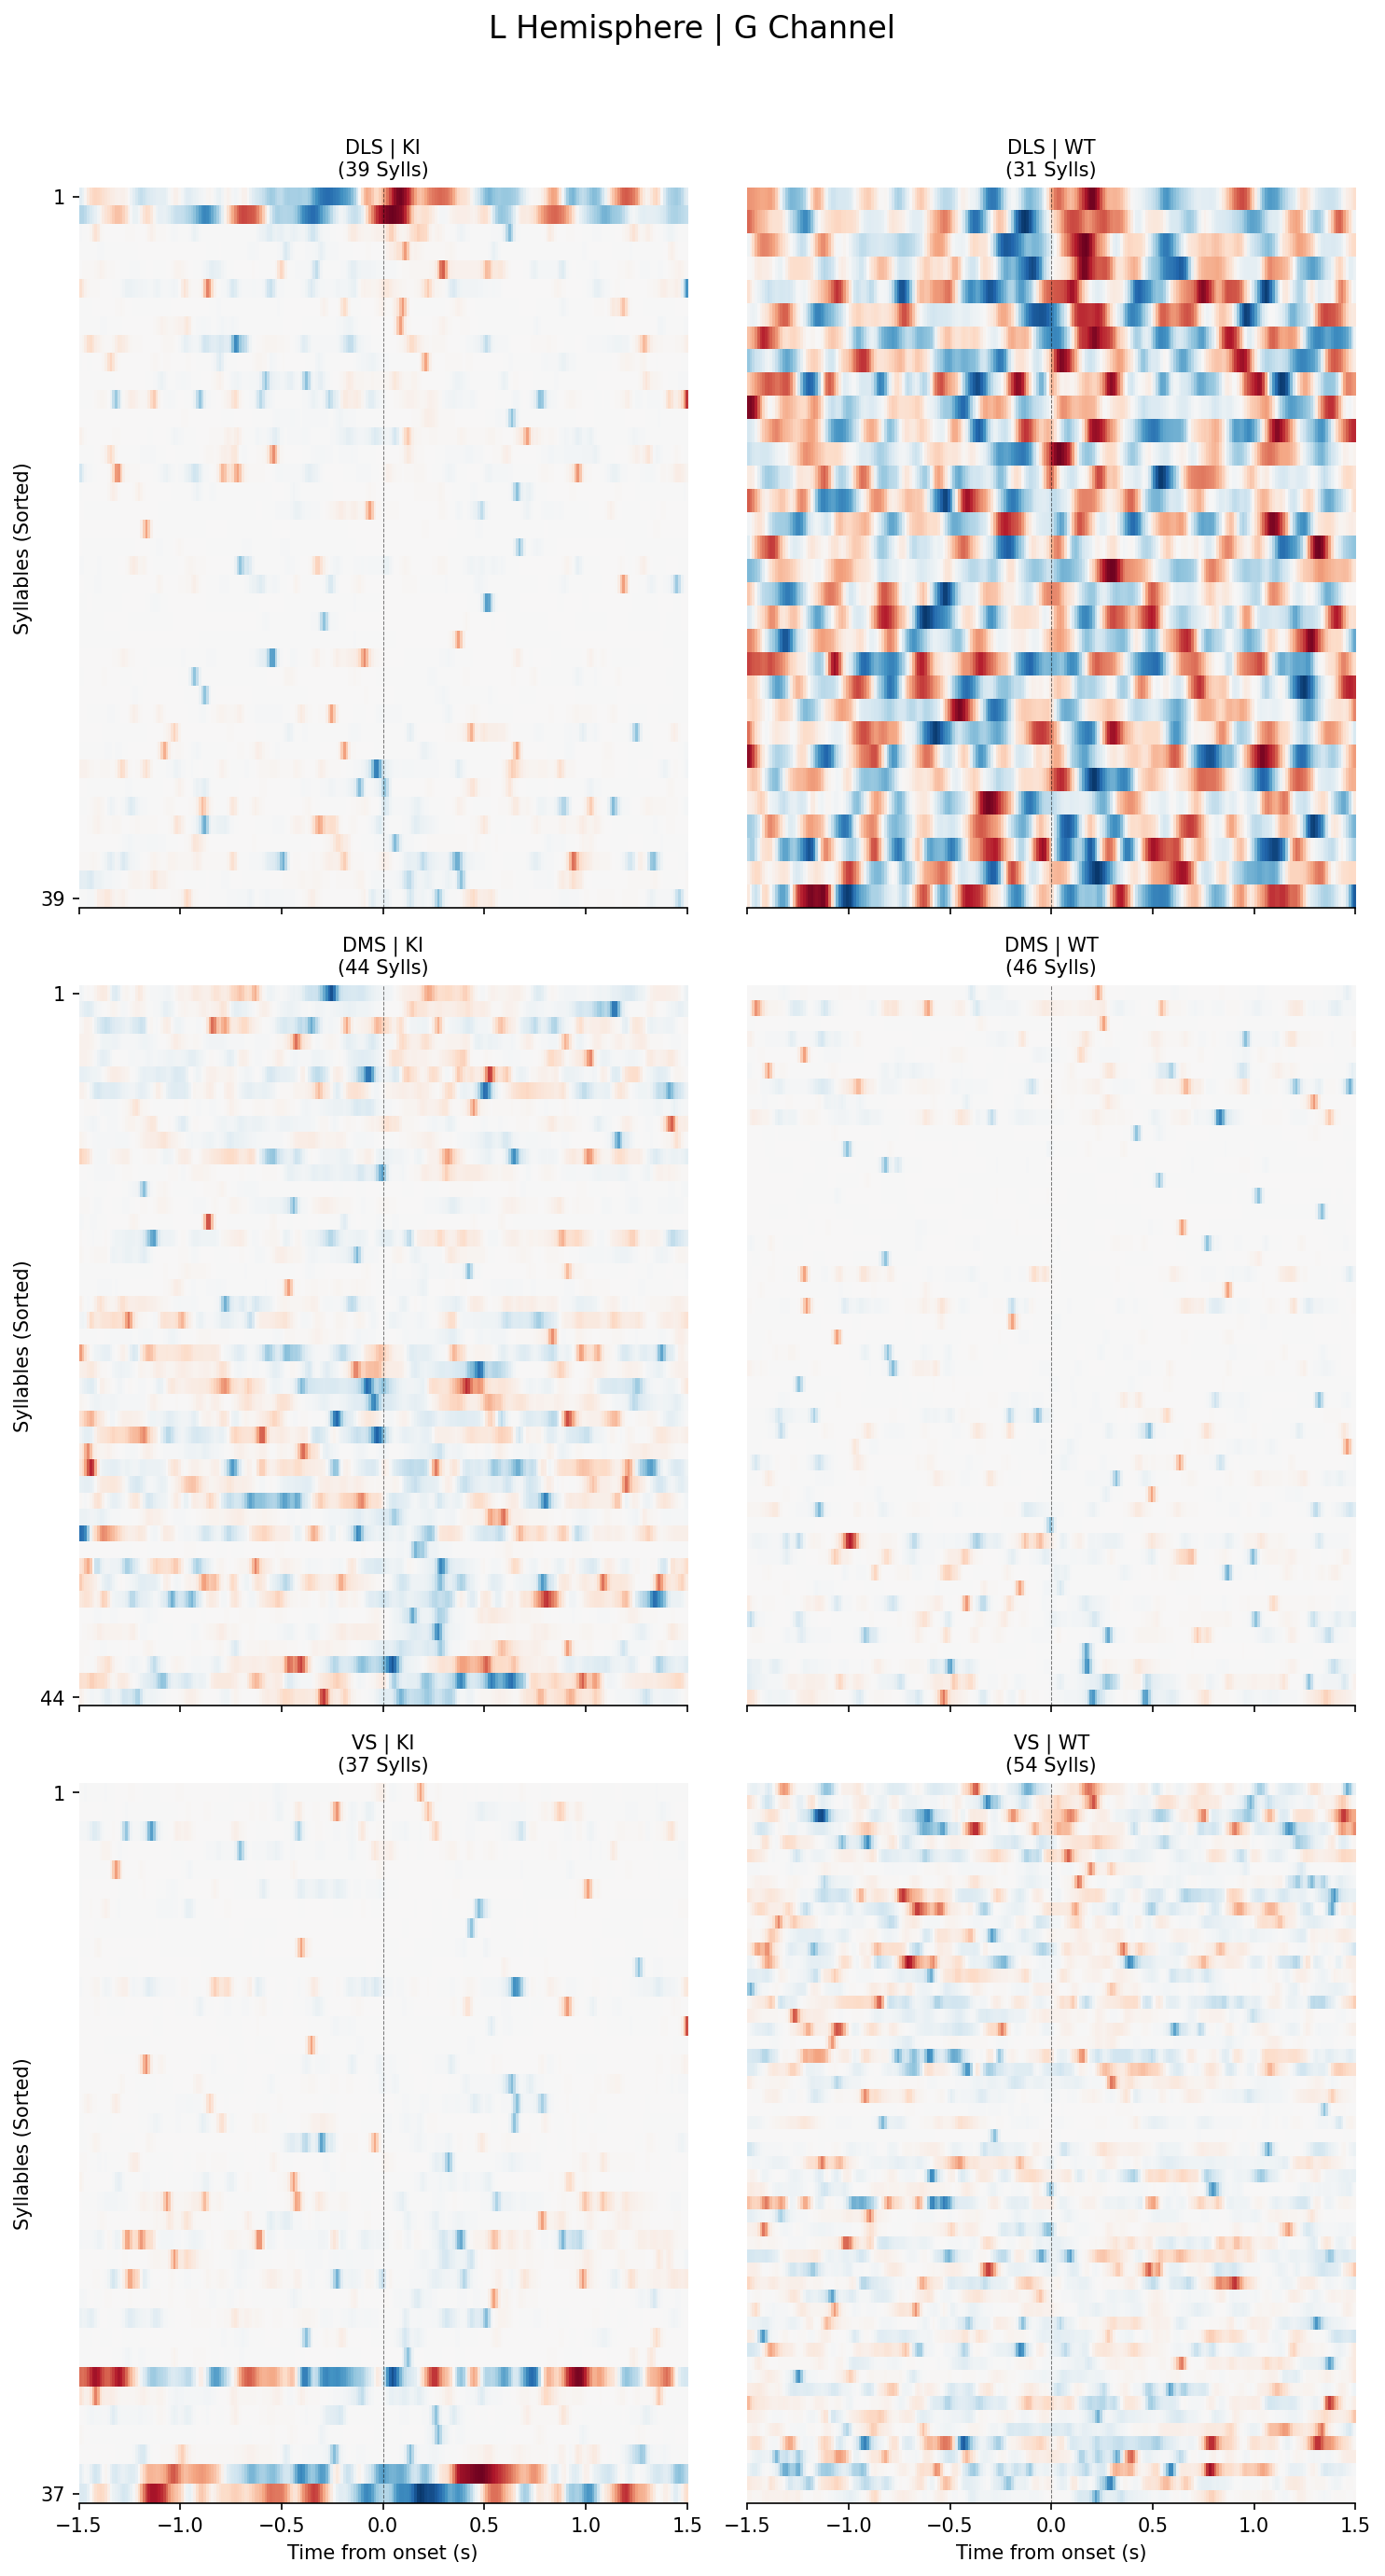


=== Plotting: R Hemisphere | G Channel ===


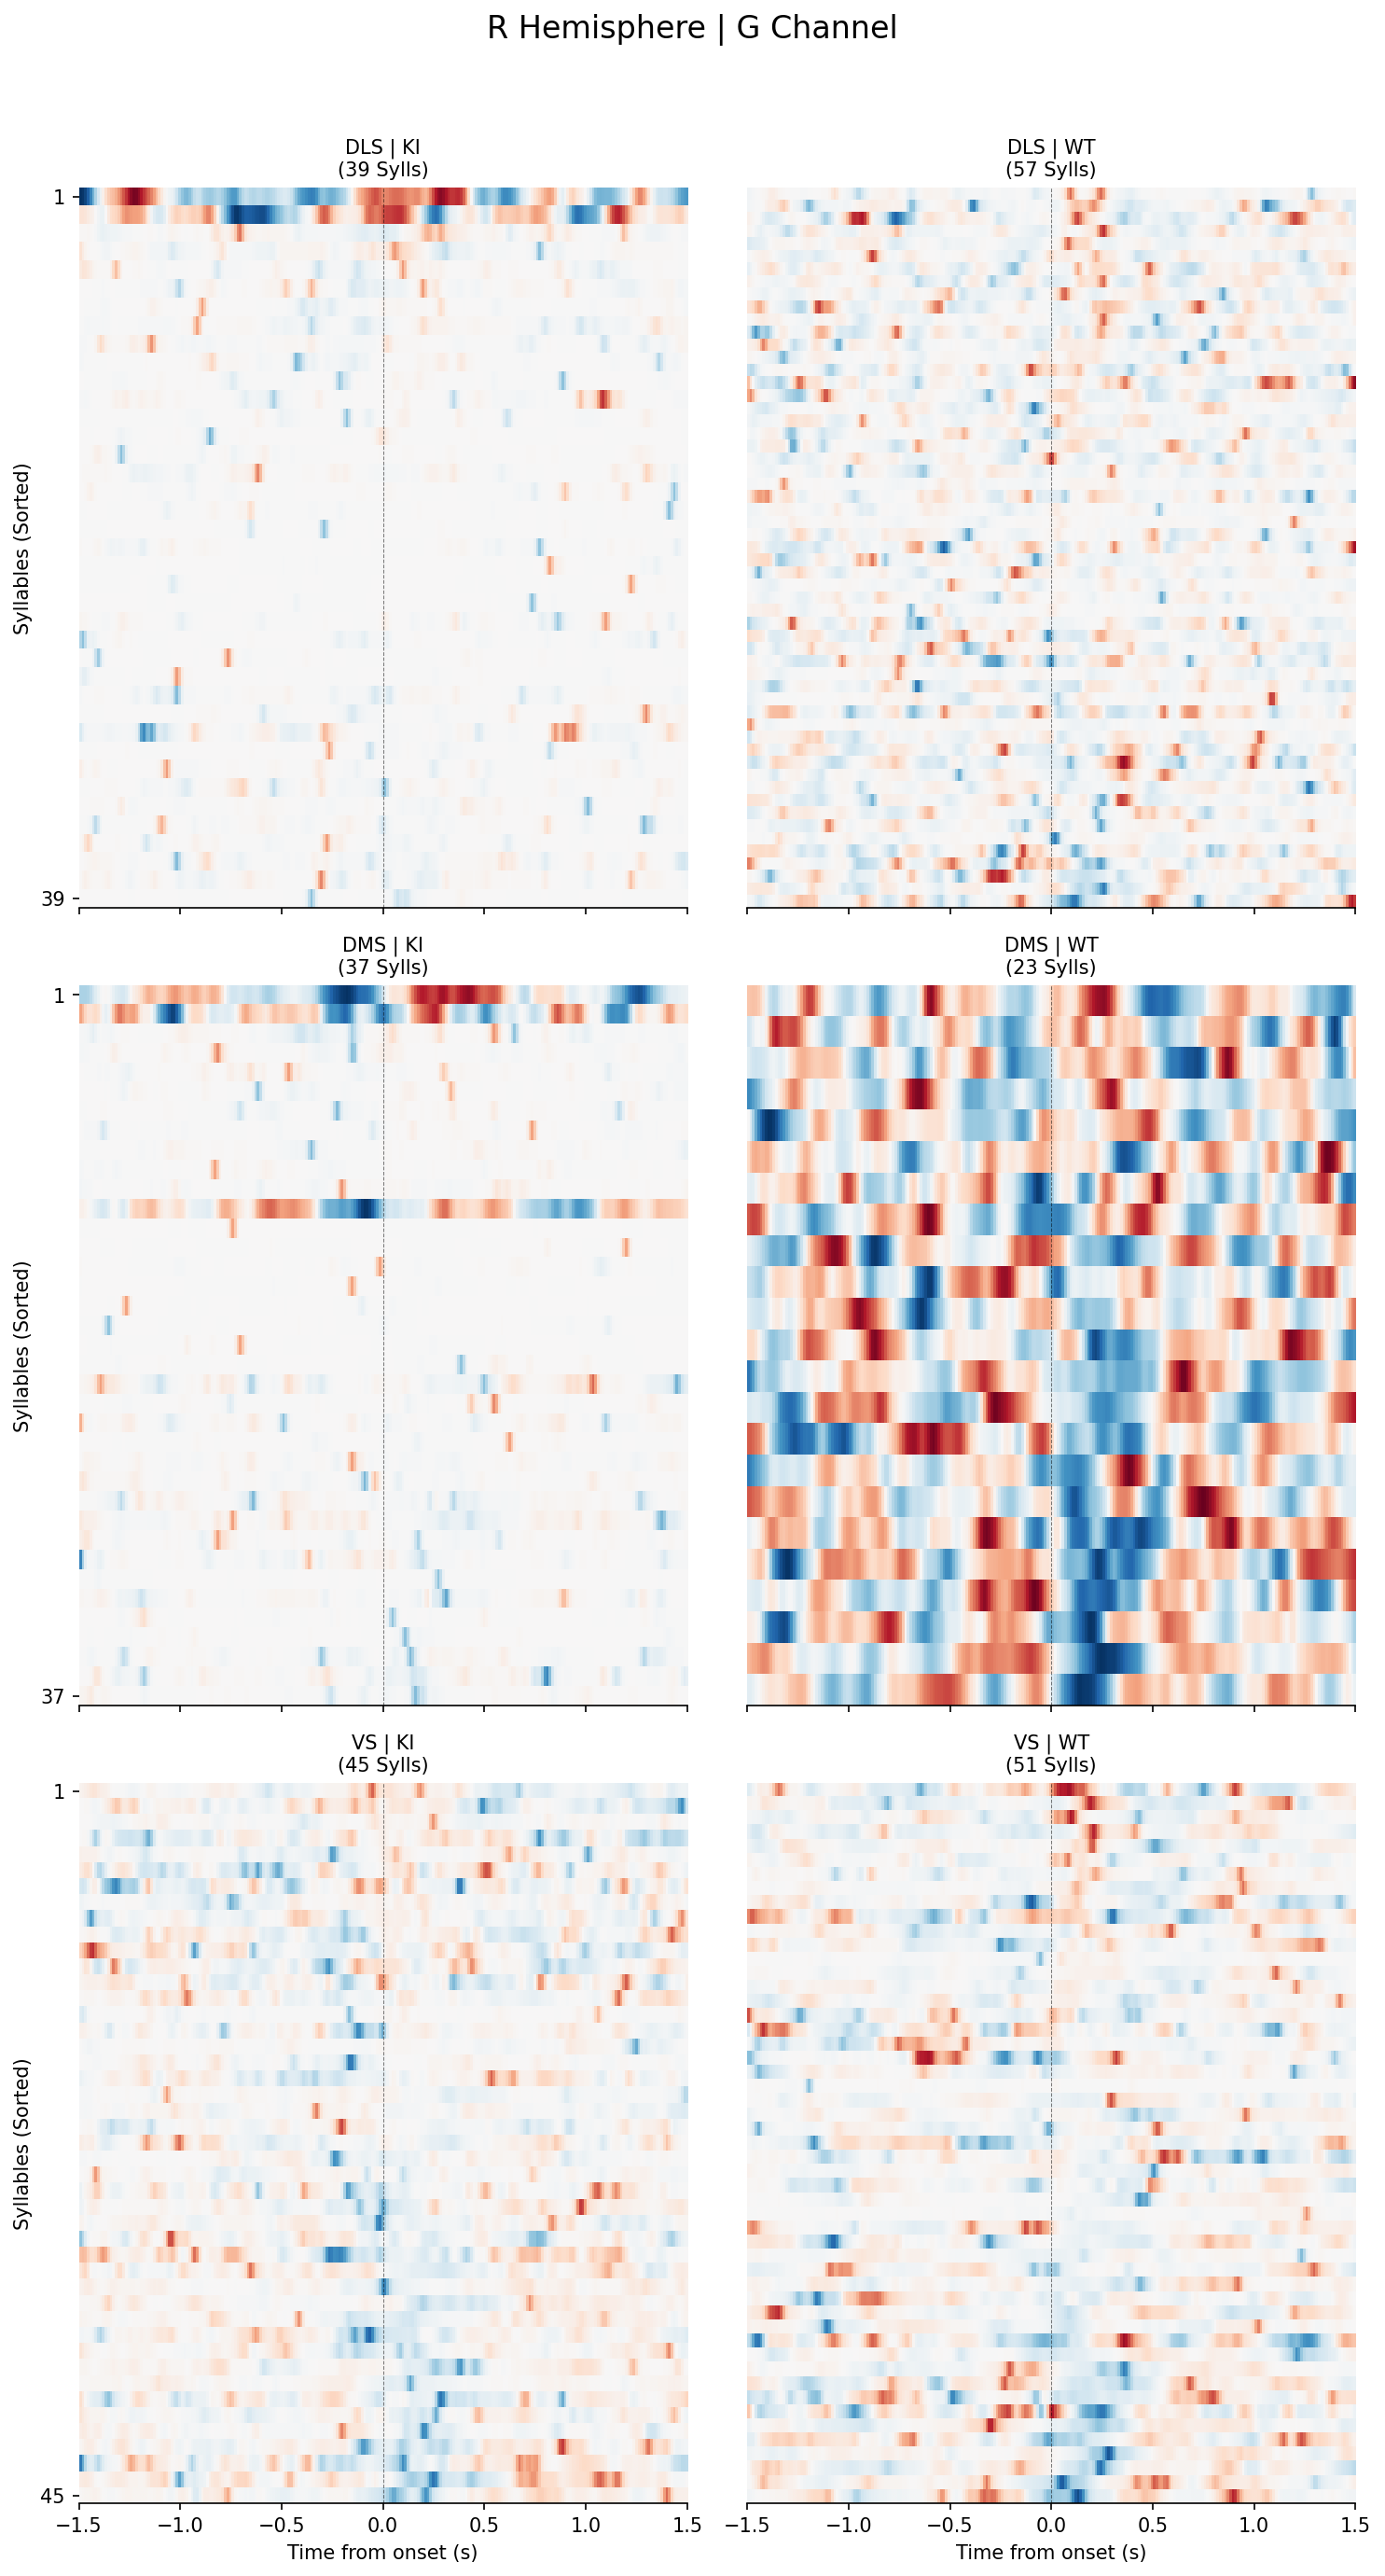


=== Plotting: L Hemisphere | R Channel ===


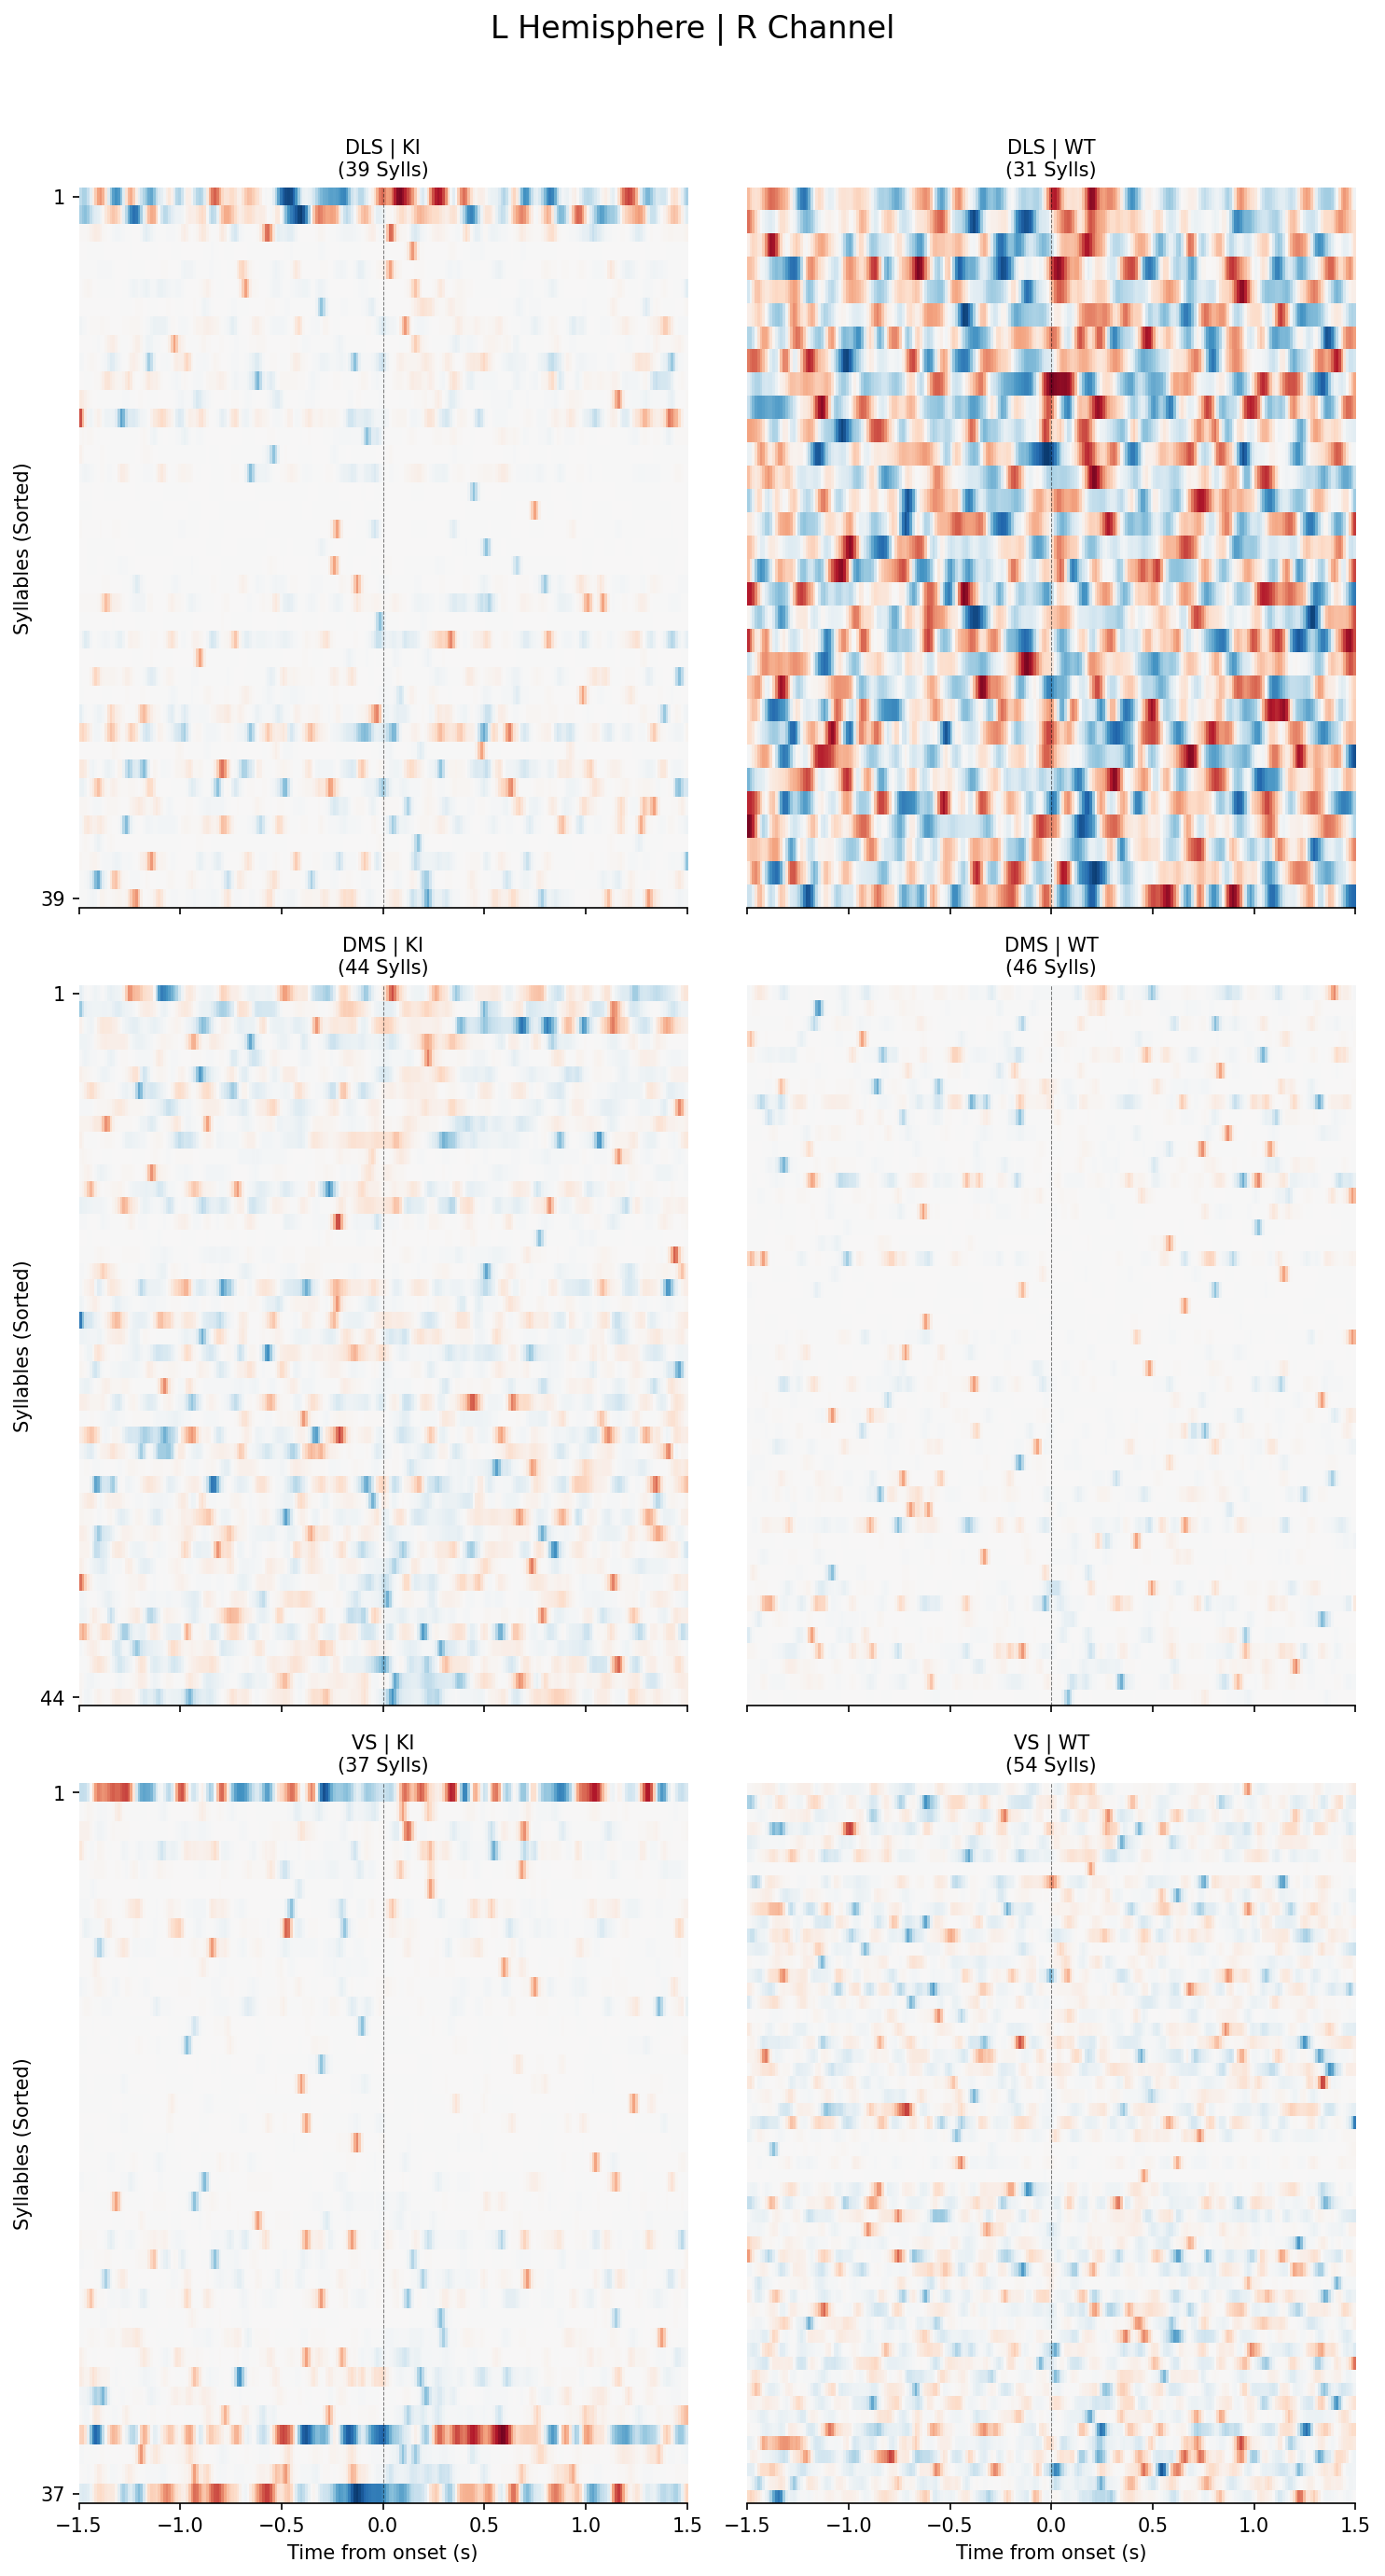


=== Plotting: R Hemisphere | R Channel ===


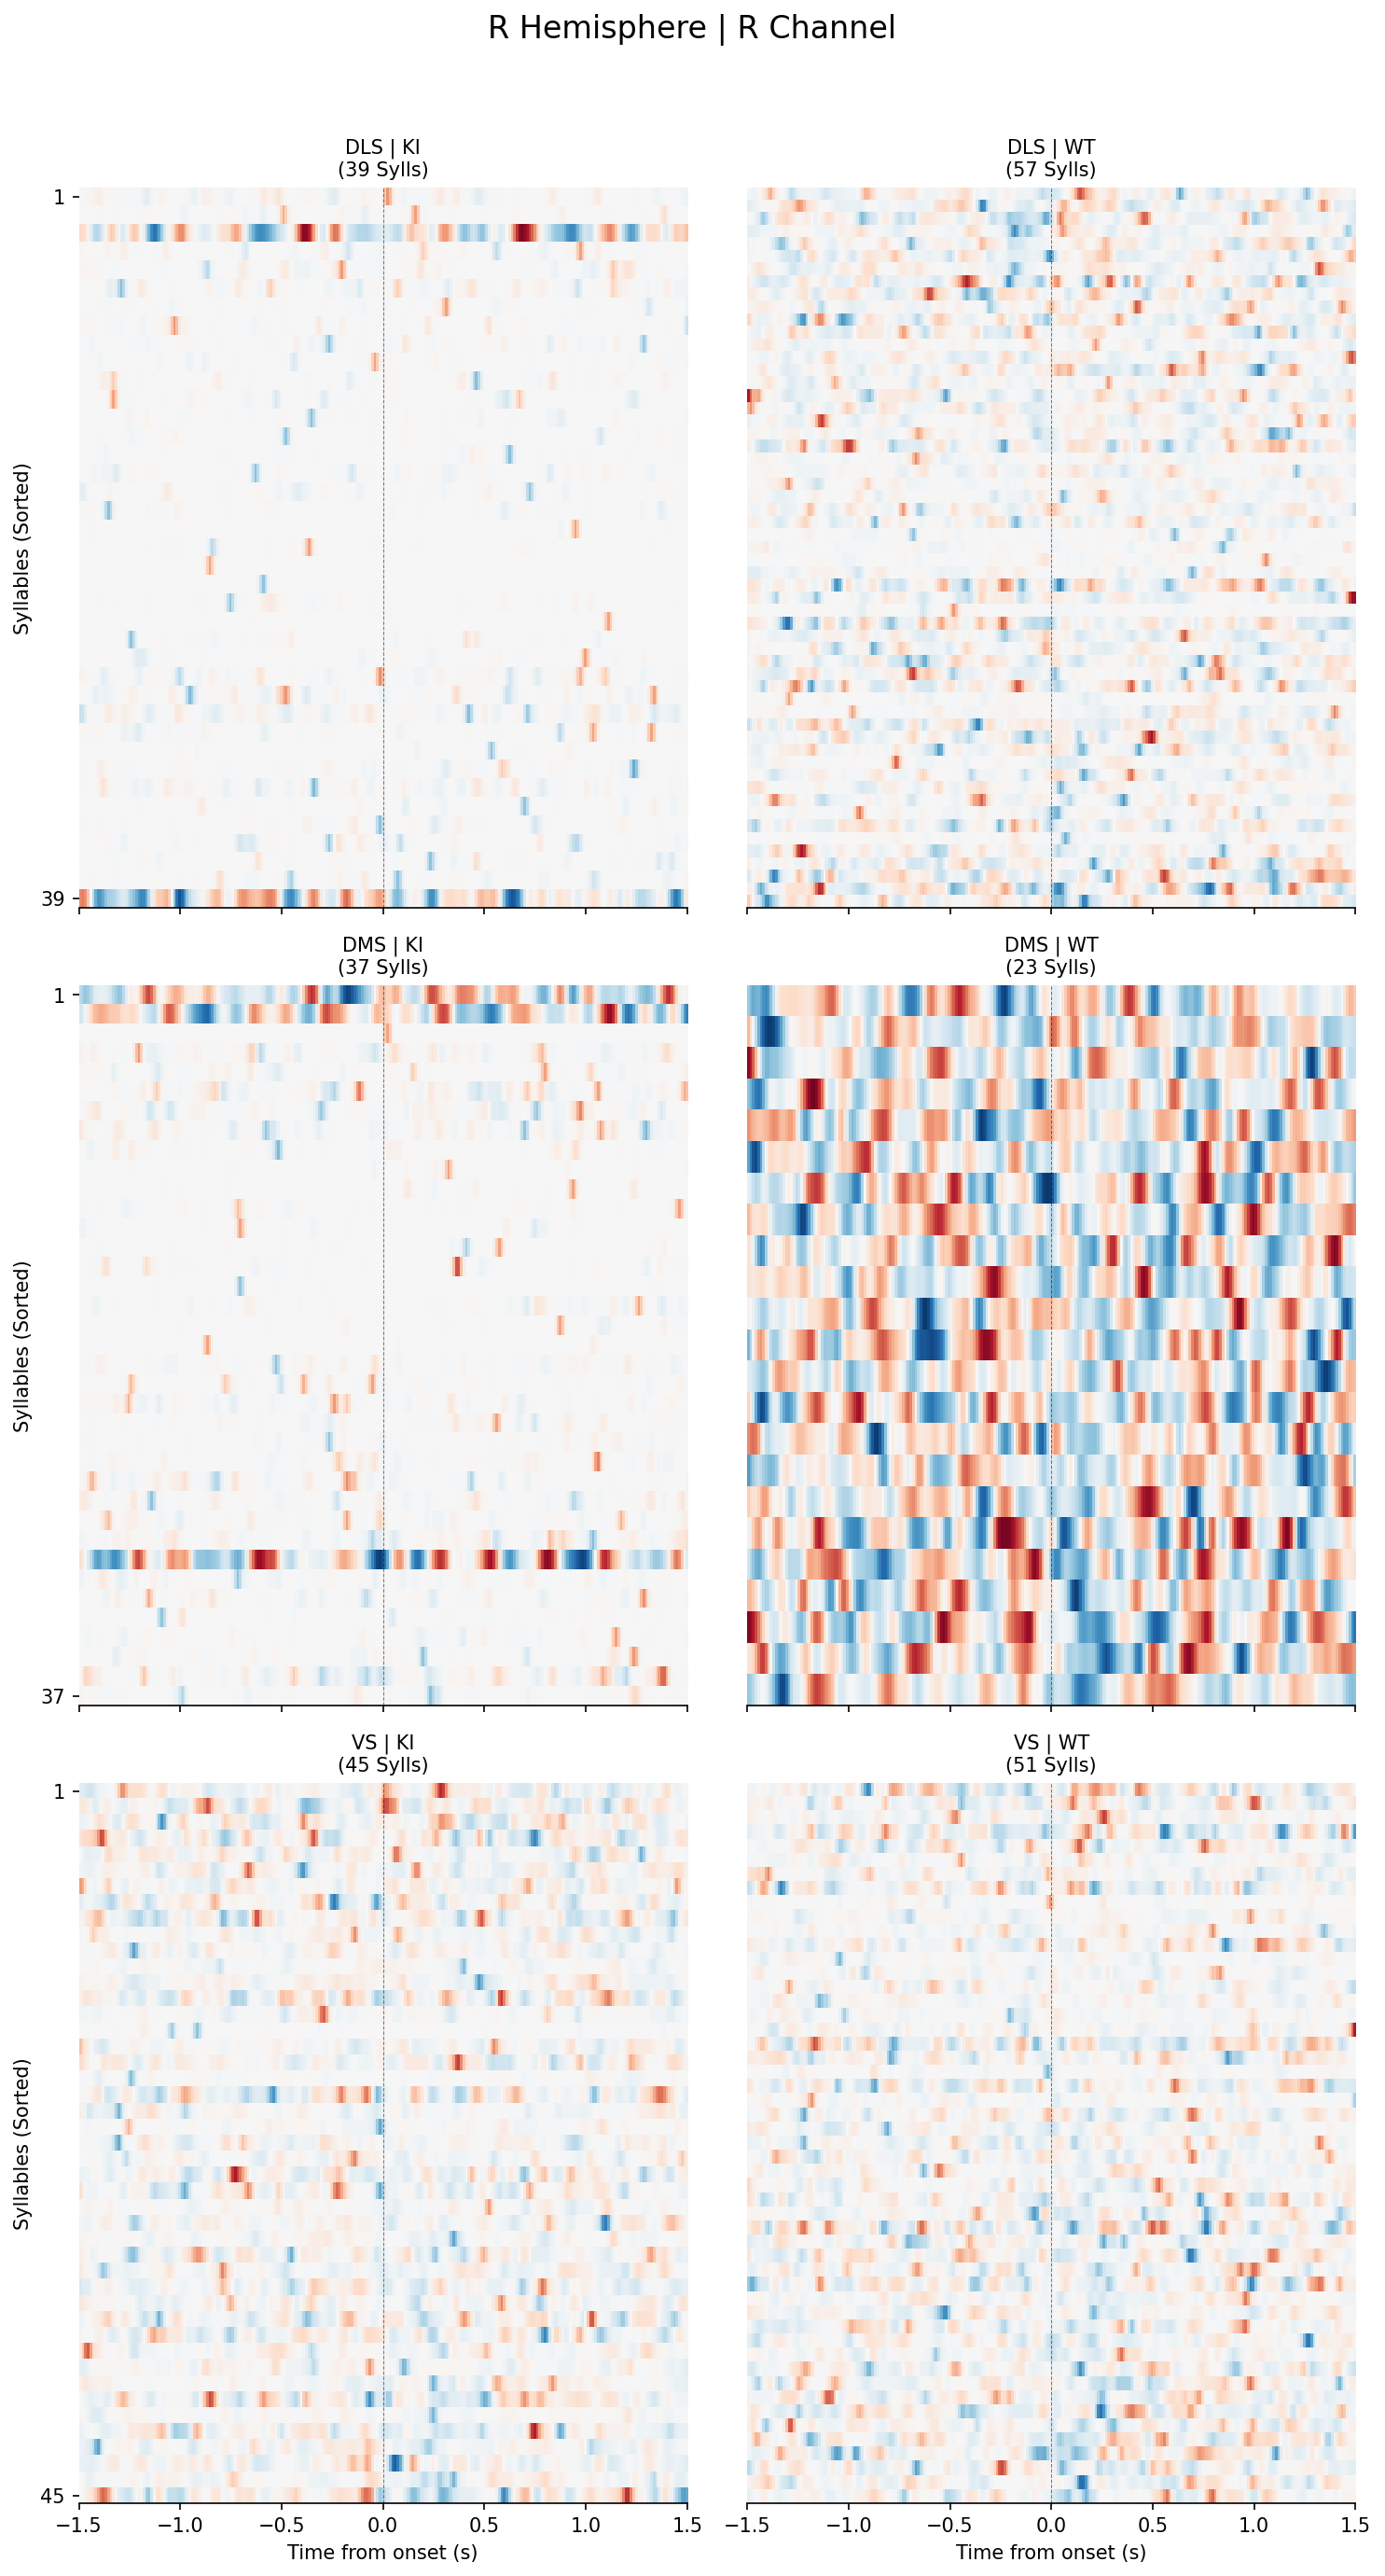

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from scipy.ndimage import gaussian_filter1d
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# --- TIME & WINDOWING ---
WINDOW_SECONDS = 1.5       
SHUFFLE_JITTER_SEC = 2.0   
N_SHUFFLES = 20            

# --- FILTERS ---
MIN_TRIALS = 50           
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# --- SEARCH SPACE (The Update) ---
TARGET_COLORS = ["G", "R"]          # Green, Red
TARGET_HEMISPHERES = ["L", "R"]     # Left, Right

# --- VISUALIZATION ---
CMAP = "RdBu_r"            
BIN_COUNT = 100            
SIGMA_TIME_SMOOTHING = 1.0 
ROW_WISE_NORM = True       

# ==========================================
# 2. HELPER: BESSEL FILTER
# ==========================================
def apply_bessel_filter(series, fs):
    nyquist = fs / 2.0
    if nyquist <= 1.0: return series
    Wn = 1.0 / nyquist
    sos = signal.bessel(1, Wn, btype="high", output="sos")
    valid_mask = ~np.isnan(series)
    result = np.full_like(series, np.nan)
    if np.sum(valid_mask) > 10:
        result[valid_mask] = signal.sosfiltfilt(sos, series[valid_mask])
    return result

# ==========================================
# 3. AGGREGATION (Split by Hemi/Color)
# ==========================================
# Deep dictionary: [geno][region][hemi][color] -> {syllable: list_of_tuples}
data_buckets = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list)))))

print(f"Scanning {len(sessions)} sessions...")
import re

def clean_region_name(raw_name):
    if not raw_name: return "UNK"
    # Remove L- or R- prefix (case insensitive) followed by any separator
    s = re.sub(r"^[LRlr][\s\-_]+", "", str(raw_name))
    return s.strip().upper()


for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate & Onsets
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    
    window_frames = int(WINDOW_SECONDS * fs)
    jitter_frames = int(SHUFFLE_JITTER_SEC * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    syllable_array = df["syllable"].to_numpy()
    
    # Process Signals
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # --- A. METADATA EXTRACTION & CLEANING ---
        raw_region = info.get("brain_reg", "UNK")
        region = clean_region_name(raw_region) 
        
        # Robust Hemisphere Check
        hemi = str(info.get("hemisphere", "")).upper()
        if not hemi or hemi == "UNK":
            # Infer from raw name (e.g. "L-DLS")
            if str(raw_region).upper().startswith("L"): hemi = "L"
            elif str(raw_region).upper().startswith("R"): hemi = "R"
        if not hemi: hemi = "UNK"

        # Robust Color Check
        color = str(info.get("orig_letter", "")).upper()
        if not color and "fiber_num" in info:
            color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
        if not color: color = "UNK"
            
        # --- B. STRICT FILTERING ---
        if region in IGNORE_REGIONS or region == "UNK": continue
        if hemi == "UNK": continue
        if color == "UNK": continue
            
        # Select Column
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        else: continue

        # Extract Trace
        raw_sig = df[col_name].to_numpy()
        filtered_sig = apply_bessel_filter(raw_sig, fs)
        max_idx = len(filtered_sig) - 1
        
        # Group Onsets by Syllable
        syll_map = defaultdict(list)
        for idx in onset_indices:
            syll_map[syllable_array[idx]].append(idx)
            
        for syll, indices in syll_map.items():
            indices = np.array(indices)
            starts = indices - window_frames
            ends = indices + window_frames
            valid = (starts >= 0) & (ends <= max_idx)
            if not np.any(valid): continue
            
            n_trials = np.sum(valid)
            
            # Actual Stack
            stack = np.array([filtered_sig[s:e] for s, e in zip(starts[valid], ends[valid])])
            if np.isnan(stack).all(): continue
            mu_actual = np.nanmean(stack, axis=0)
            
            # Shuffle Stack (Mean of N shuffles)
            shifts = np.random.randint(-jitter_frames, jitter_frames, size=(N_SHUFFLES, n_trials))
            shuff_means = []
            for i in range(N_SHUFFLES):
                s_starts = np.clip(starts[valid] + shifts[i], 0, max_idx - 2*window_frames)
                s_ends = s_starts + 2*window_frames
                s_stack = np.array([filtered_sig[s:e] for s, e in zip(s_starts, s_ends)])
                shuff_means.append(np.nanmean(s_stack, axis=0))
            mu_shuffle = np.mean(shuff_means, axis=0)
            
            # Store in deeply nested bucket
            data_buckets[geno][region][hemi][color][syll].append((n_trials, mu_actual, mu_shuffle))

# --- AUTO-DISCOVERY ---
discovered_hemis = set()
discovered_colors = set()

for g in data_buckets:
    for r in data_buckets[g]:
        for h in data_buckets[g][r]:
            discovered_hemis.add(h)
            for c in data_buckets[g][r][h]:
                discovered_colors.add(c)

TARGET_HEMISPHERES = sorted(list(discovered_hemis))
TARGET_COLORS = sorted(list(discovered_colors))

print("\n--- Aggregation Complete ---")
print(f"Discovered Hemispheres: {TARGET_HEMISPHERES}")
print(f"Discovered Colors:      {TARGET_COLORS}")

# ==========================================
# 4. PLOTTING (Iterative Generation)
# ==========================================
unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

print(f"Genotypes: {unique_genos}")
print(f"Regions: {unique_regions}")

# Loop through our Search Space
for color in TARGET_COLORS:
    for hemi in TARGET_HEMISPHERES:
        
        print(f"\n=== Plotting: {hemi} Hemisphere | {color} Channel ===")
        
        # Check Data Existence
        has_data = False
        for g in unique_genos:
            for r in unique_regions:
                if data_buckets[g][r][hemi][color]: has_data = True
        
        if not has_data:
            print("   [SKIP] No data found.")
            continue

        fig, axes = plt.subplots(
            nrows=len(unique_regions), ncols=len(unique_genos), 
            figsize=(5 * len(unique_genos), 6 * len(unique_regions)),
            dpi=150, sharex=True, sharey=False
        )

        if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
        elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
        elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

        for r_idx, region in enumerate(unique_regions):
            for c_idx, geno in enumerate(unique_genos):
                ax = axes[r_idx, c_idx]
                
                # Fetch Syllable Data for this specific combination
                syll_data = data_buckets[geno][region][hemi][color]
                
                if not syll_data:
                    ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue
                    
                z_waveforms = []
                syllables = []
                peak_metrics = []
                
                # Process Syllables
                for syll, session_list in syll_data.items():
                    total_trials = sum(item[0] for item in session_list)
                    if total_trials < MIN_TRIALS: continue
                        
                    # Weighted Mean Logic
                    weighted_actual = np.zeros_like(session_list[0][1])
                    weighted_shuffle = np.zeros_like(session_list[0][2])
                    all_shuffle_means = []
                    
                    for n, act, shuff in session_list:
                        weighted_actual += act * n
                        weighted_shuffle += shuff * n
                        all_shuffle_means.append(shuff)
                        
                    global_actual = weighted_actual / total_trials
                    global_shuffle = weighted_shuffle / total_trials
                    
                    # Z-Score
                    if len(all_shuffle_means) > 1:
                        global_shuffle_std = np.std(all_shuffle_means, axis=0)
                    else:
                        global_shuffle_std = np.ones_like(global_shuffle)
                    
                    global_shuffle_std[global_shuffle_std == 0] = 1.0
                    z_trace = (global_actual - global_shuffle) / global_shuffle_std
                    
                    # Normalize & Smooth
                    if ROW_WISE_NORM:
                        max_val = np.max(np.abs(z_trace))
                        if max_val > 0: z_trace /= max_val
                    
                    if SIGMA_TIME_SMOOTHING > 0:
                        z_trace = gaussian_filter1d(z_trace, sigma=SIGMA_TIME_SMOOTHING)
                    
                    z_waveforms.append(z_trace)
                    syllables.append(syll)
                    
                    # Sort Metric (Peak in onset window)
                    idx_0 = len(z_trace) // 2
                    idx_end = idx_0 + int(len(z_trace) * 0.1)
                    peak_metrics.append(np.mean(z_trace[idx_0:idx_end]))
                    
                if not z_waveforms:
                    ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue
                    
                # Plot
                z_matrix = np.array(z_waveforms)
                sort_idx = np.argsort(peak_metrics)[::-1]
                z_sorted = z_matrix[sort_idx]
                
                plot_vmax = 1.0 if ROW_WISE_NORM else np.percentile(np.abs(z_sorted), 99)
                
                im = ax.imshow(
                    z_sorted,
                    aspect="auto",
                    cmap=CMAP,
                    vmin=-plot_vmax, vmax=plot_vmax,
                    interpolation="nearest",
                    extent=(-WINDOW_SECONDS, WINDOW_SECONDS, len(z_sorted), 0)
                )
                
                ax.axvline(0, color="black", linestyle="--", linewidth=0.5, alpha=0.5)
                ax.set_title(f"{region} | {geno}\n({len(z_sorted)} Sylls)", fontsize=10)
                
                if c_idx == 0:
                    ax.set_ylabel("Syllables (Sorted)")
                    ax.set_yticks([0.5, len(z_sorted)-0.5])
                    ax.set_yticklabels(["1", str(len(z_sorted))])
                else: ax.set_yticks([])
                
                if r_idx == len(unique_regions)-1:
                    ax.set_xlabel("Time from onset (s)")
                    
                sns.despine(ax=ax, left=True, bottom=False)

        # Super Title
        plt.suptitle(f"{hemi} Hemisphere | {color} Channel", y=1.02, fontsize=16)
        plt.tight_layout()
        plt.show()